# GAN (Generative Adversarial Networks)

En este practico vamos a estar implementando el modelo generativo [GAN (Generative Adversarial Networks)](https://arxiv.org/pdf/1406.2661)

In [1]:
import math
import torch
import numpy as np
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import torch.nn.functional as F
import torchvision.utils as vutils
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from mpl_toolkits.axes_grid1 import ImageGrid

In [2]:
# Transformamos los datos a tensores y los normalizamos
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
    ])

# Descargamos el dataset
dataset = datasets.FashionMNIST(root='./data', download=True, transform=transform)

# Creamos el dataloader
batch_size = 64
dataloader = DataLoader(dataset=dataset, batch_size=batch_size, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Running on {device}")

100%|██████████| 26.4M/26.4M [00:14<00:00, 1.84MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 268kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.49MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.9MB/s]

Running on mps


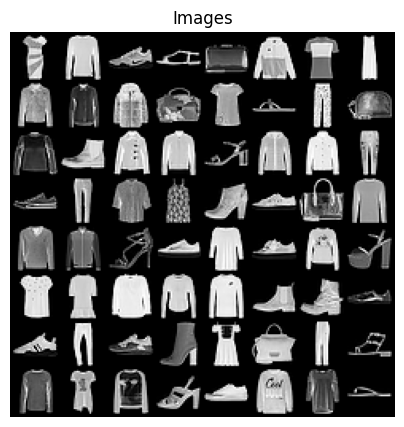

In [3]:
def show_imgs(imgs, title="Images"):
    plt.figure(figsize=(5,5))
    plt.axis("off")
    plt.title(title)
    plt.imshow(np.transpose(vutils.make_grid(imgs, padding=2, normalize=True).cpu(),(1,2,0)))
    plt.show()

real_batch = next(iter(dataloader))[0][:64]
img_shape = real_batch[0].shape
show_imgs(real_batch)

## Definimos el modelo
Las GANs (Generative Adversarial Networks) consisten en dos redes que compiten entre sí: un generador que crea datos falsos y un discriminador que trata de distinguirlos de los datos reales, mejorando así la calidad de los datos generados con el tiempo.

### Generador
Es una red neuronal que, partiendo de un espacio latente, crea datos sintéticos con el objetivo de parecerse a los datos reales.

Esta "parte" del modelo es la que nos va a servir luego para la generación.

In [4]:
class Generator(nn.Module):
    def __init__(self, latent_dim, number_feature_maps, output_channels):
        super(Generator, self).__init__()
        self.latent_feature_maps = latent_dim
        self.main = nn.Sequential(
            # Tamaño entrada (bs, tamaño latente, 1, 1)
            nn.ConvTranspose2d(latent_dim, number_feature_maps * 4, 7, 1, 0, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*4, 7 , 7)
            nn.ConvTranspose2d(number_feature_maps * 4, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*2, 14 , 14)
            nn.ConvTranspose2d(number_feature_maps * 2, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps, 28 , 28)
            nn.ConvTranspose2d(number_feature_maps, output_channels, 3, 1, 1, bias=False),
            nn.Tanh(),
            # Tamaño salida (bs, 1, 28 , 28)
        )

    def forward(self, input):
        result = self.main(input)
        return result

### Discriminador

Es una red neuronal que clasifica los datos como reales o generados. Su tarea es distinguir entre los datos reales y los falsos producidos por el generador, ayudando así a mejorar la calidad de ambos.

In [5]:
class Discriminator(nn.Module):
    def __init__(self, input_channels, number_feature_maps, output_dim):
        super(Discriminator, self).__init__()
        self.conv_layers = nn.Sequential(
            # Tamaño entrada (bs, 1, 28, 28)
            nn.Conv2d(input_channels, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps, 14, 14)
            nn.Conv2d(number_feature_maps, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*2, 7, 7)
            nn.Conv2d(number_feature_maps * 2, number_feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*4, 4, 4)
        )

        self.fully_connected = nn.Sequential(
            nn.Flatten(1),
            # Tamaño (bs, 3*3*number_feature_maps*4)
            nn.Linear(3*3*number_feature_maps*4, output_dim),
            nn.Sigmoid()
        )

    def forward(self, input):
        res = self.conv_layers(input)
        res = self.fully_connected(res)
        return res

## Definición de hyperparámetros y creación del modelo.

In [21]:
# Definimos hyperparámetros
latent_dim = 10
discriminator_lr = 0.0002
generator_lr = 0.002
n_epochs = 12

# Creamos el generador y el discriminador
generator = Generator(latent_dim, 64, 1).to(device)
discriminator = Discriminator(1, 64, 1).to(device)

# Definir la función de pérdida
adversarial_loss = torch.nn.BCELoss()

In [22]:
# Definimos la función de entrenamiento del modelo
def train(generator, discriminator, adversarial_loss, dataloader, n_epochs, device, verbose=False):
    # Creamos los dos optimizadores. 
    # Recordar que estos optimizadores son distintos ya que cada uno precisa los parametros
    #    a entrenar y el discriminador y el generador se entrenan por separado.
    
    
    generator.to(device) # Movemos el generador al dispositivo y el discriminador también
    discriminator.to(device)
    optimizer_G = optim.Adam(generator.parameters(), lr=generator_lr)
    optimizer_D = optim.Adam(discriminator.parameters(), lr=discriminator_lr)

    for epoch in tqdm(range(n_epochs)):
        for i, (imgs, _) in enumerate(dataloader):
            bs = imgs.size(0)

            # Creamos las etiquetas para el discriminador
            valid = torch.ones(bs, 1, device=device)
            fake = torch.zeros(bs, 1, device=device)

            real_imgs = imgs.to(device)

            # Creamos ruido dentro del espacio latente usando una normal
            latent_shape = (bs, latent_dim, 1, 1)
            z = torch.randn(latent_shape, device=device)

            
            # Entrenar el generador
            optimizer_G.zero_grad()
            gen_imgs = generator(z)
            g_loss = adversarial_loss(discriminator(gen_imgs), valid)
            g_loss.backward()
            optimizer_G.step()

            # Entrenar el discrminador (recordar hacer el detach de las imagenes generadas)
            optimizer_D.zero_grad()
            real_loss = adversarial_loss(discriminator(real_imgs), valid)
            fake_loss = adversarial_loss(discriminator(gen_imgs.detach()), fake)
            d_loss = (real_loss + fake_loss) / 2
            d_loss.backward()
            optimizer_D.step()

            if verbose: print(f"[Epoch {epoch}/{n_epochs}] [Batch {i}/{len(dataloader)}] [D loss: {d_loss.item()}] [G loss: {g_loss.item()}]")

        if epoch % 4 == 0:
                show_imgs(gen_imgs.data[:32], title=f"Epoch {epoch}")
            


## Entrenamiento del modelo

  0%|          | 0/12 [00:00<?, ?it/s]

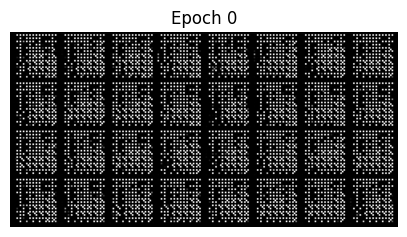

 33%|███▎      | 4/12 [03:05<06:11, 46.45s/it]

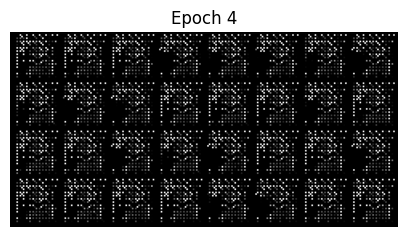

 67%|██████▋   | 8/12 [06:07<03:02, 45.66s/it]

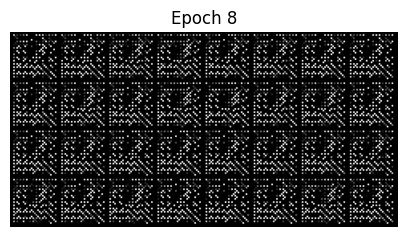

100%|██████████| 12/12 [09:14<00:00, 46.22s/it]


In [23]:
# Comenzamos el entrenamiento del modelo!
train(generator, discriminator, adversarial_loss, dataloader, n_epochs, device)

[nota del estudiante]: Como puede observarse, la calidad de las imágenes generadas no son buenas, no visualizándose objetos claros. Probaremos modificando la dimensión del espacio latente, y volviendo a entrenar las redes.

  0%|          | 0/12 [00:00<?, ?it/s]

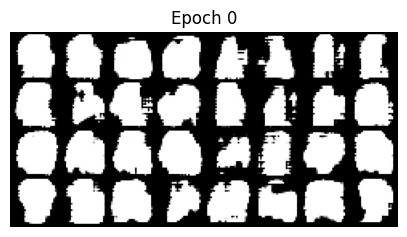

 33%|███▎      | 4/12 [03:41<07:23, 55.42s/it]

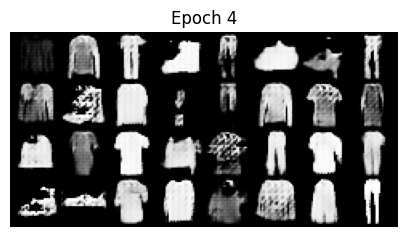

 67%|██████▋   | 8/12 [07:22<03:39, 54.89s/it]

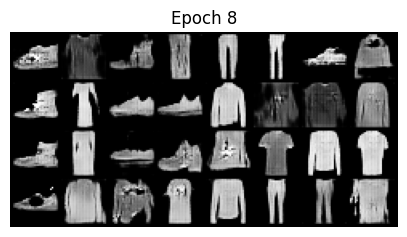

100%|██████████| 12/12 [10:59<00:00, 54.97s/it]


In [24]:
# Definimos hyperparámetros
latent_dim = 100
discriminator_lr = 0.0002
generator_lr = 0.002
n_epochs = 12

# Creamos el generador y el discriminador
generator_2 = Generator(latent_dim, 64, 1).to(device)
discriminator_2 = Discriminator(1, 64, 1).to(device)

# Definir la función de pérdida
adversarial_loss_2 = torch.nn.BCELoss()

train(generator_2, discriminator_2, adversarial_loss_2, dataloader, n_epochs, device)

[nota del estudiante]: Ahora, se observan imágenes "coherentes" por lo que podemos concluir que el aumento de la dimensionalidad del espacio latente, permitió capturar de mejor forma la "realidad" de los datos. Procederemos a generar a continuación los datos, a partir del nuevo generador.

## Generación de datos

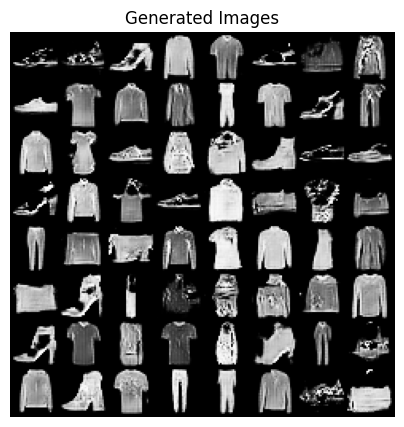

In [ ]:
def generate(generator, num_imgs=32):
    # Creamos un tensor de ruido dentro del espacio latente
    z = torch.randn(num_imgs, latent_dim, 1, 1, device=device)
    # Hacemos el forward pass del generador
    gen_imgs = generator(z)
    return gen_imgs

imgs = generate(generator_2, num_imgs=64)
show_imgs(imgs, title="Generated Images")

## Ejercicios:

1. Complete el codigo faltante y entrene una GAN que genere imágenes de Fashion MNIST.
2. Responda las siguientes preguntas:
    - ¿En qué afecta el tamaño del espacio latente?
    - ¿Por qué entrenamos al discriminador y al generador alternativamente?
    - ¿Qué tamaño tiene la salida del discriminador y por qué? ¿Y el generador?
    - ¿Qué tipo de activación final se usa en el discriminador y por qué?
    - ¿Cuál es el propósito de la competencia entre el generador y el discriminador en las GANs? Explica cómo esto contribuye a la mejora del modelo.
    - Entrene una GAN que genere imágenes del dataset [SVHN (street view house number)](http://ufldl.stanford.edu/housenumbers/).
    - Comente los resultados obtenidos con este dataset.

Estas imágenes son de (3, 32, 32). Debe crear un nuevo generador y dicriminador para ajustarse a estas nuevas dimensiones.

Image size: torch.Size([3, 32, 32])


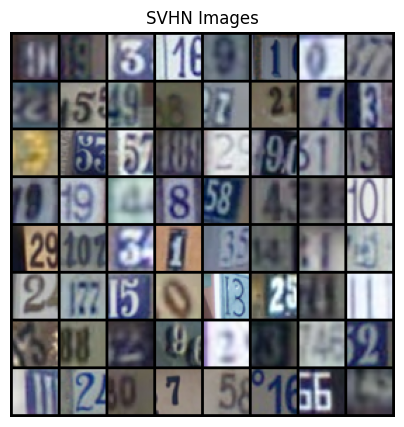

In [47]:
transform = transforms.Compose([
    transforms.ToTensor(),
    # transforms.Normalize(0, 1)
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

dataset = datasets.SVHN(root='./data', download=True, transform=transform)
print(f"Image size: {dataset[0][0].shape}")

batch_size = 64
dataloader = DataLoader(dataset=dataset, batch_size=batch_size, shuffle=True)
real_batch = next(iter(dataloader))[0]
img_shape = real_batch[0].shape
show_imgs(real_batch, "SVHN Images")

**[nota del estudiante]** Se responden a continuación las preguntas realizadas.

- ¿En qué afecta el tamaño del espacio latente?

**[nota del estudiante]** El espacio latente afecta en la "forma", o "complejidad" de la distribución aprendida de los datos. De alguna manera, cuanto mayor la dimensionalidad del espacio latente, mayor conocimiento "intrínseco" de los datos, y cómo éstos se vinculan. Por ejemplo, poder capturar la relación entre los píxeles de los ojos, la distancia entre ellos, etc., se logra a través de la distribución conjunta del espacio latente.

- ¿Por qué entrenamos al discriminador y al generador alternativamente?

**[nota del estudiante]** Existen diversos motivos, pero el principal es para prevenir el desequilibrio. Por ejemplo, si el discriminador es demasiado "estricto" clasificando todo como "falso", la función de pérdida del generador se "saturaría" y daría gradientes casi nulo, evitando el aprendizaje de la red del generador.

- ¿Qué tamaño tiene la salida del discriminador y por qué? ¿Y el generador?

**[nota del estudiante]** La salida del discriminador es 1, ya que al tratarse de un "clasificador", el mismo devuelve "verdadero" o "falso". En tanto el generador, depende de los datos que estemos tratando. En el caso del tratamiento de las imágenes en escala de grises, se trata de una sola dimensión. Para el caso de imágenes en RGB -por ejemplo-, deberíamos utilizar 3 canales.

- ¿Qué tipo de activación final se usa en el discriminador y por qué?

**[nota del estudiante]** Se utiliza Binary Cross Entropy porque se trata de un clasificador.

- ¿Cuál es el propósito de la competencia entre el generador y el discriminador en las GANs? Explica cómo esto contribuye a la mejora del modelo.

**[nota del estudiante]** Lograr que la red del generador mejore la calidad de los datos generados, haciendo que las imágenes -para este caso- sean de mejor calidad. Esto se logra ya que el generador, va aprendiendo progresivamente la distribución "latente" de los datos reales.

**[nota del estudiante]** Procedemos ahora a ajustar los modelos para el entrenamiento de este nuevo dataset

In [43]:
# Definimos el nuevo generador para que se ajuste a las dimensiones de las imágenes con color
class Generator(nn.Module):
    def __init__(self, latent_dim, number_feature_maps, output_channels):
        super(Generator, self).__init__()
        self.latent_feature_maps = latent_dim
        self.main = nn.Sequential(
            # Tamaño entrada (bs, tamaño latente, 1, 1)
            # Actualizamos a 8 el kernel para que logremos la salida de 32 x 32 en lugar de 28 x 28
            nn.ConvTranspose2d(latent_dim, number_feature_maps * 4, 8, 1, 0, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*4, 8 , 8)
            nn.ConvTranspose2d(number_feature_maps * 4, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*2, 16 , 16)
            nn.ConvTranspose2d(number_feature_maps * 2, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps, 32 , 32)
            nn.ConvTranspose2d(number_feature_maps, output_channels, 3, 1, 1, bias=False),
            nn.Tanh(),
            # Tamaño salida (bs, 1, 32 , 32)
        )

    def forward(self, input):
        result = self.main(input)
        return result

In [44]:
class Discriminator(nn.Module):
    def __init__(self, input_channels, number_feature_maps, output_dim):
        super(Discriminator, self).__init__()
        self.conv_layers = nn.Sequential(
            # Tamaño entrada (bs, 3, 32, 32)
            nn.Conv2d(input_channels, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps, 16, 16)
            nn.Conv2d(number_feature_maps, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*2, 8, 8)
            nn.Conv2d(number_feature_maps * 2, number_feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*4, 4, 4)
        )

        self.fully_connected = nn.Sequential(
            nn.Flatten(1),
            # Tamaño (bs, 4*4*number_feature_maps*4)
            nn.Linear(4*4*number_feature_maps*4, output_dim),
            nn.Sigmoid()
        )

    def forward(self, input):
        res = self.conv_layers(input)
        res = self.fully_connected(res)
        return res

  0%|          | 0/36 [00:00<?, ?it/s]

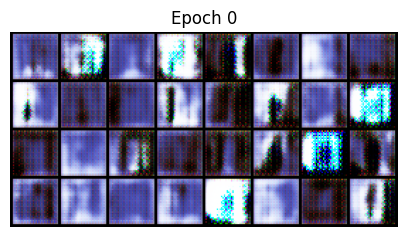

 11%|█         | 4/36 [04:56<39:36, 74.26s/it]

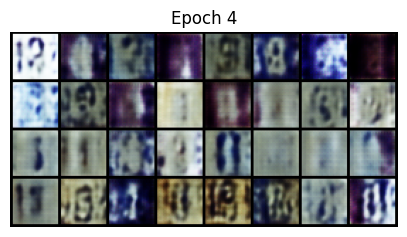

 22%|██▏       | 8/36 [09:46<33:51, 72.54s/it]

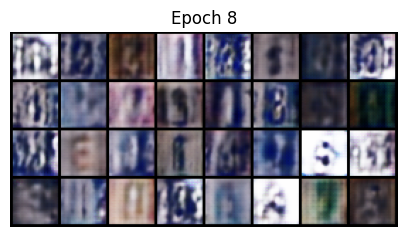

 33%|███▎      | 12/36 [14:33<28:43, 71.82s/it]

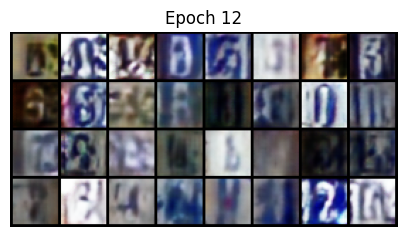

 44%|████▍     | 16/36 [19:16<23:38, 70.93s/it]

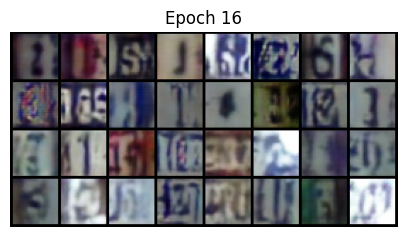

 56%|█████▌    | 20/36 [23:59<18:55, 70.98s/it]

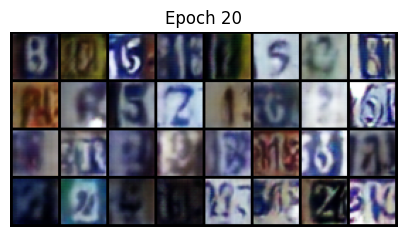

 67%|██████▋   | 24/36 [28:44<14:13, 71.13s/it]

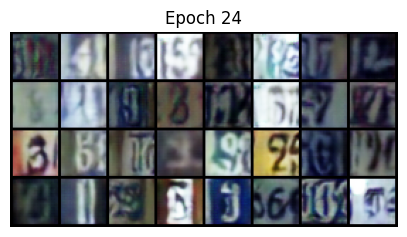

 78%|███████▊  | 28/36 [33:22<09:19, 69.92s/it]

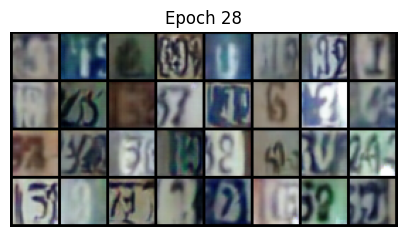

 89%|████████▉ | 32/36 [1:14:34<29:35, 443.83s/it]

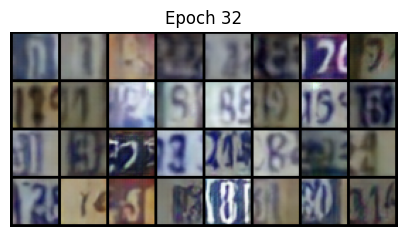

100%|██████████| 36/36 [1:41:47<00:00, 169.66s/it]


In [63]:
# Definimos hyperparámetros
latent_dim = 150
discriminator_lr = 0.0002
generator_lr = 0.0002
n_epochs = 36

# Creamos el generador y el discriminador
generator_3 = Generator(latent_dim,64, 3).to(device) # Aumentamos a 3 los canales ya que las imágenes tienen color
discriminator_3 = Discriminator(3, 64, 1).to(device)

# Definir la función de pérdida
adversarial_loss_3 = torch.nn.BCELoss()

train(generator_3, discriminator_3, adversarial_loss_3, dataloader, n_epochs, device)

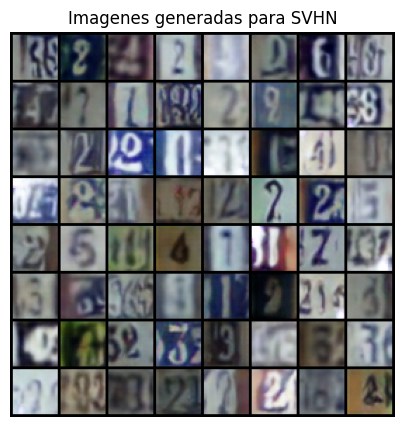

In [64]:
imgs = generate(generator_3, num_imgs=64)
show_imgs(imgs, title="Imagenes generadas para SVHN")

**[nota del estudiante]** Como puede observarse, el modelo (generador) que se entrenó si bien muestra imágenes que se asemejan al dataset de SVHN, aún queda "espacio" de optimización. Por ejemplo, se podría modificar los hiperparámetros del modelo, modificar el learning rate, las dimensiones latentes, etc. Incluso, eventualmente se podría modificar las capas del generador.